# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import VHR10Dataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import csv

## Visualize images and objects witn bounding boxes

Total number of patches: 650


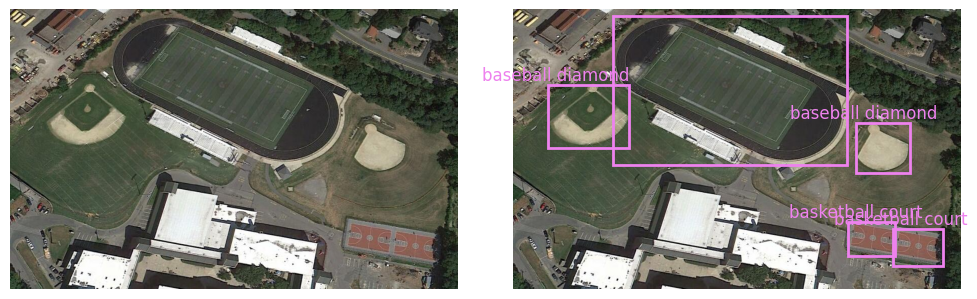

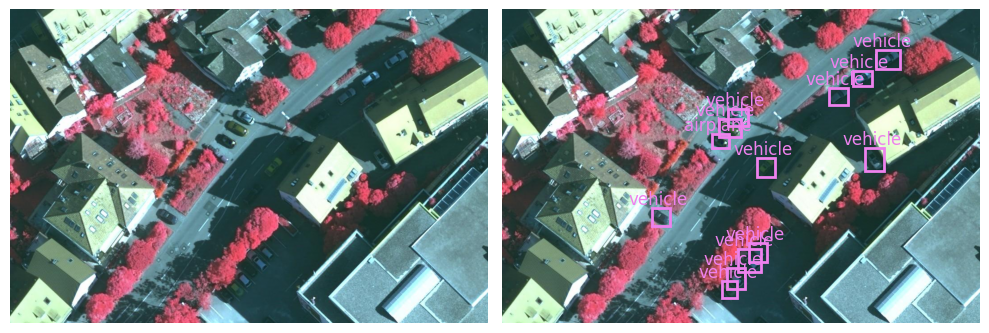

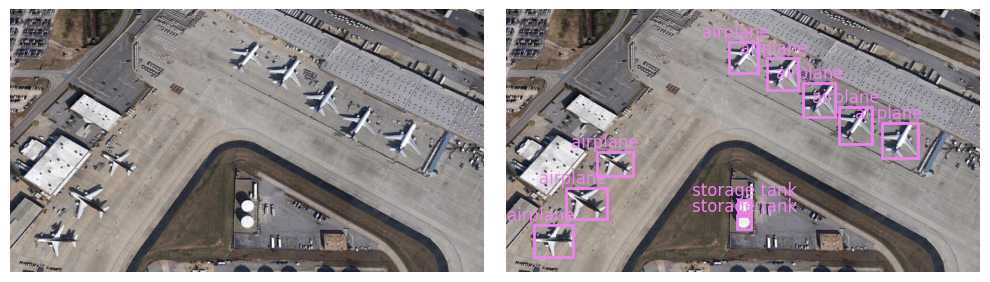

In [ ]:
dataset_config = {
    "data_dir": "./data/VHR-10/positive_image_set/",
    "annotation_dir": "./data/VHR-10/ground_truth/",
}
dataset = VHR10Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(5);
dataset.show_image(10);
dataset.show_image(100);

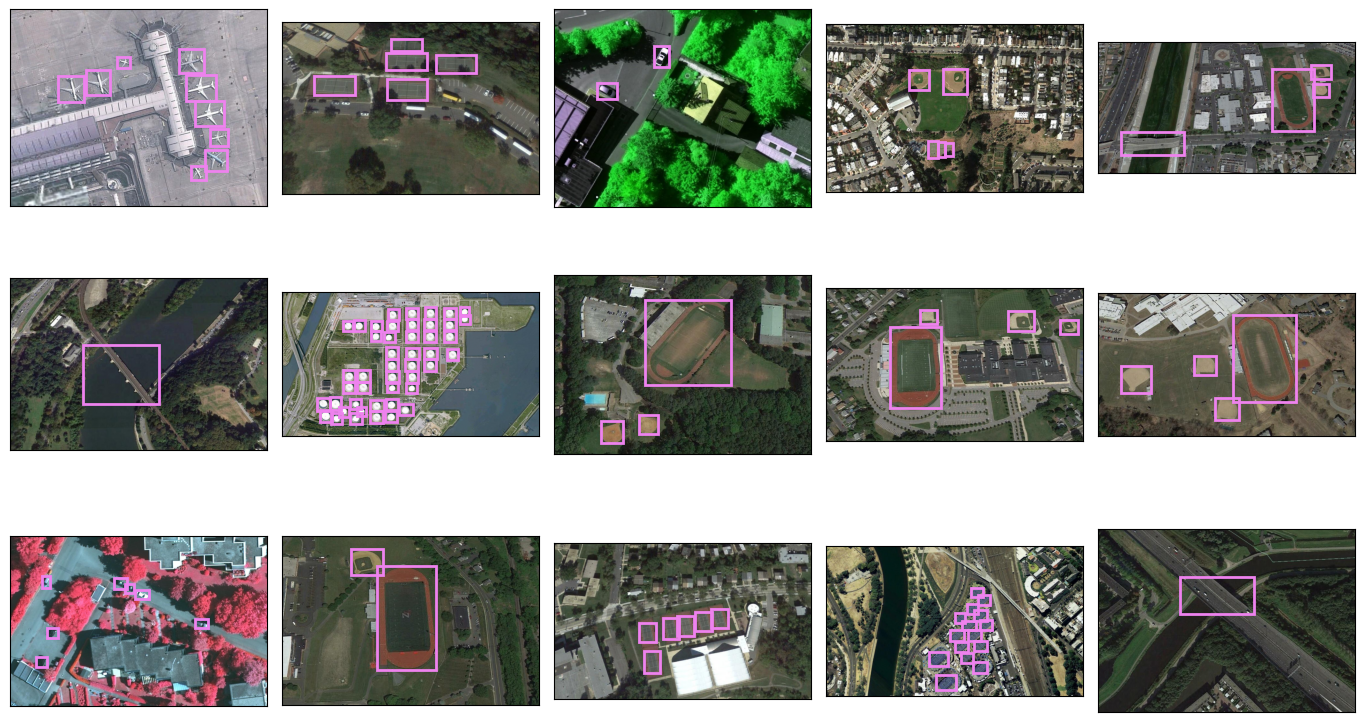

In [6]:
dataset.show_batch(15);

In [7]:
dataset.data_distribution_table()

,Label,Count
0,airplane,565
1,storage tank,238
2,ship,587
3,baseball diamond,309
4,tennis court,463
5,basketball court,137
6,ground track field,81
7,harbor,162
8,bridge,77
9,vehicle,517


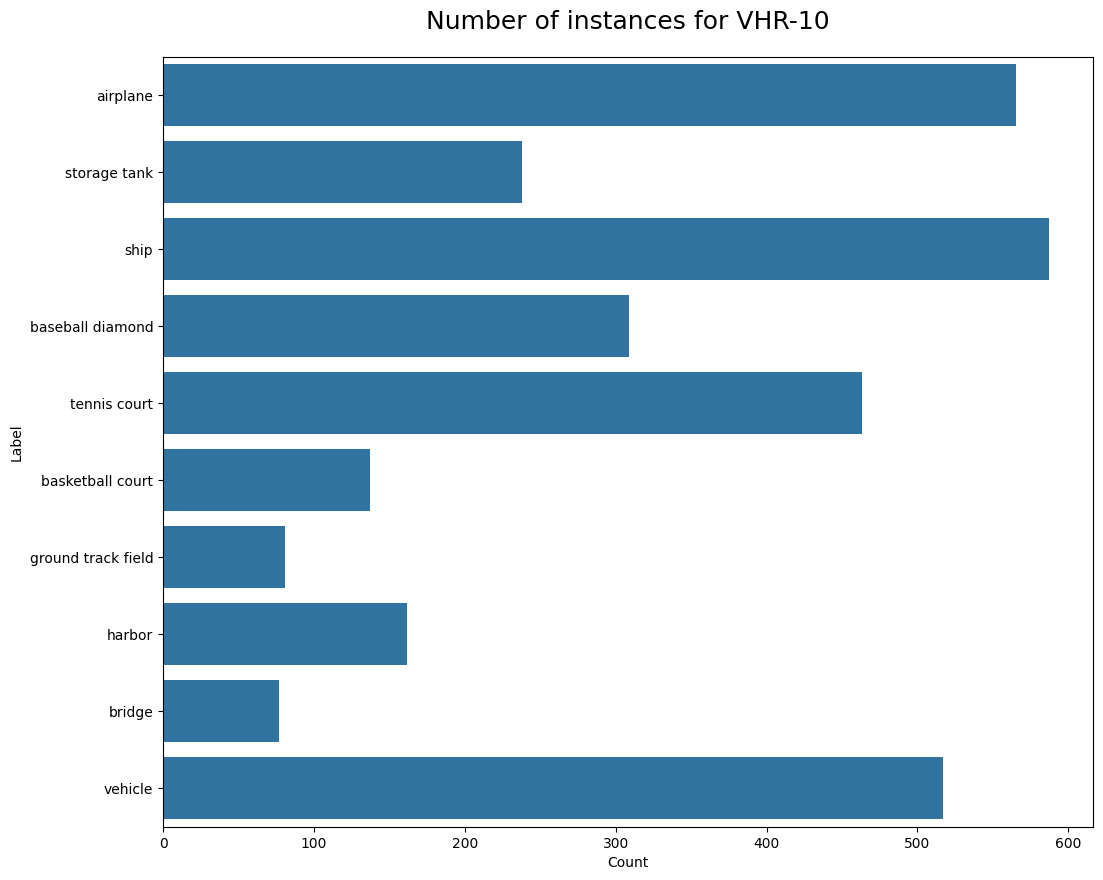

In [8]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/VHR-10/positive_image_set/",
    "annotation_dir": "./data/VHR-10/ground_truth/",
    "csv_file":"./data/VHR-10/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = VHR10Dataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 520


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/VHR-10/experiments/"
model_config = {
    "num_classes": 11,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-04-28 10:01:58,456 INFO Starting training.
training: 100%|██████████| 65/65 [00:21<00:00,  2.96it/s]
2025-04-28 10:02:20,786 INFO epoch: 1, time: 22, loss:  0.78080
testing on train set: 100%|██████████| 65/65 [00:11<00:00,  5.60it/s]
2025-04-28 10:02:36,069 INFO map:0.39702939987182617, map_50:0.6997430324554443, map_75:0.4109114706516266, map_small:0.33046427369117737, map_medium:0.379260778427124, map_large:0.3138604164123535, mar_1:0.16015967726707458, mar_10:0.39467594027519226, mar_100:0.4609929621219635, mar_small:0.40195003151893616, mar_medium:0.4261609613895416, mar_large:0.33519628643989563, map_per_class:tensor(0.6148), tensor(0.5492), tensor(0.4248), tensor(0.6272), tensor(0.4849), tensor(0.0215), tensor(0.7221), tensor(0.1929), tensor(0.0132), tensor(0.3198), mar_100_per_class:tensor(0.6776), tensor(0.6133), tensor(0.5394), tensor(0.6972), tensor(0.5930), tensor(0.0173), tensor(0.7704), tensor(0.2379), tensor(0.0380), tensor(0.4258), classes:tensor(1, dtype=torch.int

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/VHR-10/positive_image_set/",
    "annotation_dir": "./data/VHR-10/ground_truth/",
    "csv_file":"./data/VHR-10/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = VHR10Dataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/VHR-10/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 65


2025-04-28 10:08:30,469 INFO Loading checkpoint /home/dragik/data/FAIR_EO/VHR-10/experiments/checkpoint.pth.tar
2025-04-28 10:08:30,851 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/VHR-10/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 9/9 [00:02<00:00,  3.91it/s]


[{'map': 0.590417206287384,
  'map_50': 0.9243945479393005,
  'map_75': 0.6526111960411072,
  'map_small': 0.6043685674667358,
  'map_medium': 0.640740692615509,
  'map_large': 0.5244740843772888,
  'mar_1': 0.24928823113441467,
  'mar_10': 0.5948591828346252,
  'mar_100': 0.6368483304977417,
  'mar_small': 0.6429522037506104,
  'mar_medium': 0.6765895485877991,
  'mar_large': 0.5583333373069763,
  'map_per_class': [tensor(0.6691),
   tensor(0.6082),
   tensor(0.2222),
   tensor(0.7078),
   tensor(0.7005),
   tensor(0.7250),
   tensor(0.7957),
   tensor(0.5000),
   tensor(0.3483),
   tensor(0.6273)],
  'mar_100_per_class': [tensor(0.7145),
   tensor(0.6710),
   tensor(0.3056),
   tensor(0.7745),
   tensor(0.7576),
   tensor(0.7667),
   tensor(0.8250),
   tensor(0.5000),
   tensor(0.3750),
   tensor(0.6787)],
  'classes': [tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32),
   tensor(4, dtype=torch.int32),
   tensor(5, dtype=torch.int32),
   t

## Predictions

2025-04-28 10:08:39,461 INFO Loading checkpoint /home/dragik/data/FAIR_EO/VHR-10/experiments/checkpoint.pth.tar
2025-04-28 10:08:39,846 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/VHR-10/experiments/checkpoint.pth.tar at epoch 11


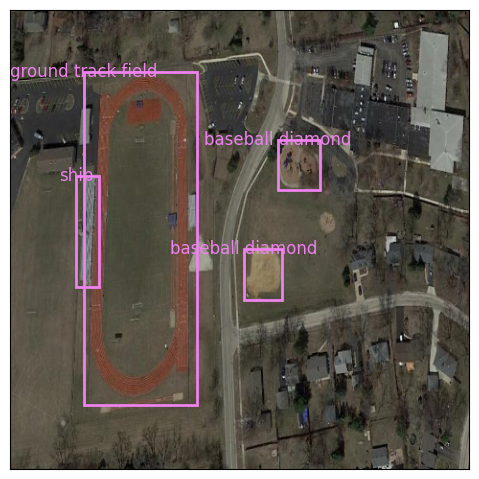

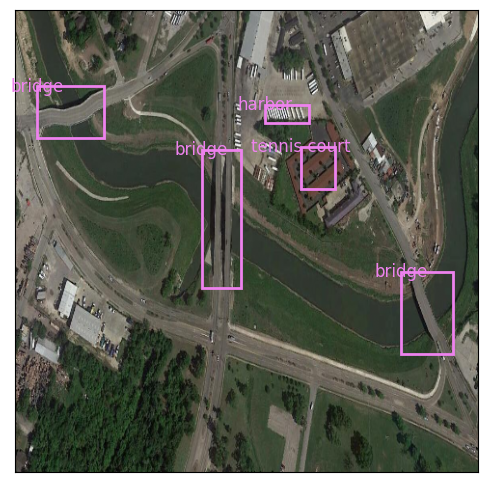

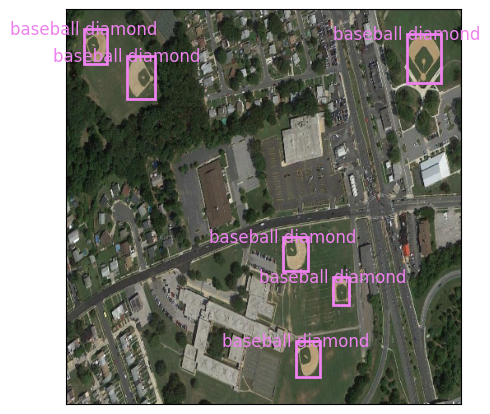

In [ ]:
model_config = {
    "num_classes": 11,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/VHR-10/experiments/checkpoint.pth.tar"
labels = ["no-data","airplane","ship","storage tank","baseball diamond","tennis court","basketball court","ground track field","harbor","bridge","vehicle"]
transform = Resize()
model.load_model(model_path)

csv_file = "./data/VHR-10/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0].split('/')[1])

image = image_loader('./data/VHR-10/positive_image_set/' + test_list[0])
image = image[:,:,0:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/VHR-10/positive_image_set/' + test_list[1])
image = image[:,:,0:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/VHR-10/positive_image_set/' + test_list[10])
image = image[:,:,0:3]
fig = model.detect_objects(image, labels, transform)